# Churn: which customers are likely to leave?

**Data:** IBM *Telco Customer Churn* (7,043 customers, target `Churn`).
**Output in LeadPilot:** `Contact.churn_risk` (probability) for every customer with a won deal.

Money is in USD per month in Telco but in rupee deals in our CRM, so spend and product counts
are converted to **percentile ranks within each dataset**. Tenure stays in months.

In [1]:
import os, sys, warnings
from pathlib import Path

BACKEND = Path.cwd().resolve().parents[1]  # backend/ml/notebooks -> backend
sys.path.insert(0, str(BACKEND))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
BLUE = "#2a78d6"

In [2]:
from ml.pipelines import churn, datasets
raw = datasets.load_telco()
print(raw.shape, "churn rate:", round((raw["Churn"] == "Yes").mean(), 3))
raw.head(3)

(7043, 21) churn rate: 0.265


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


## 1. EDA

Blank TotalCharges: 11 (all tenure 0: True )


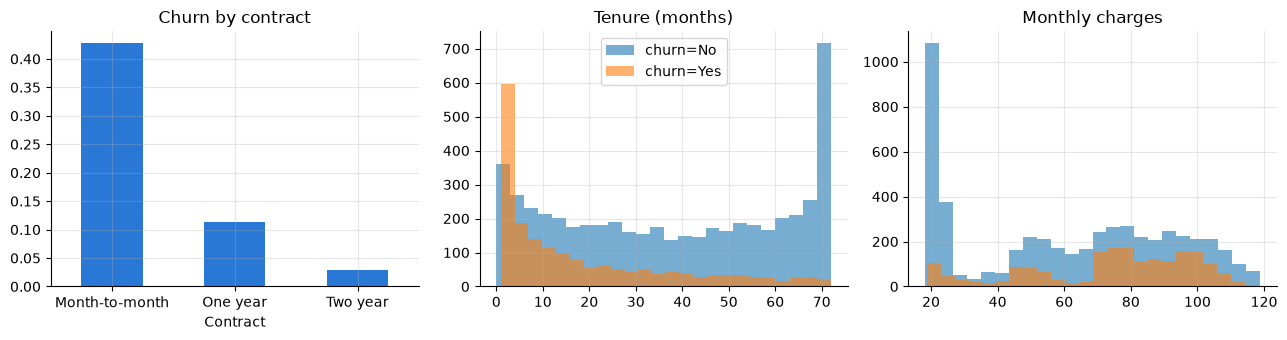

In [3]:
raw["TotalCharges"] = pd.to_numeric(raw["TotalCharges"], errors="coerce")
print("Blank TotalCharges:", raw["TotalCharges"].isna().sum(), "(all tenure 0:",
      raw.loc[raw["TotalCharges"].isna(), "tenure"].eq(0).all(), ")")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
raw.groupby("Contract")["Churn"].apply(lambda s: (s == "Yes").mean()).plot.bar(ax=axes[0], color=BLUE, title="Churn by contract", rot=0)
for label, grp in raw.groupby("Churn"):
    axes[1].hist(grp["tenure"], bins=24, alpha=0.6, label=f"churn={label}")
    axes[2].hist(grp["MonthlyCharges"], bins=24, alpha=0.6, label=f"churn={label}")
axes[1].set_title("Tenure (months)"); axes[2].set_title("Monthly charges"); axes[1].legend()
plt.tight_layout()

- Month-to-month customers churn ~4x more than 2-year contracts → a *commitment* feature.
- New customers (low tenure) and high monthly charges churn more.
- The 11 blank `TotalCharges` are brand-new customers (tenure 0): filled with 0, not dropped.

## 2. Feature mapping

In [4]:
X, y = churn.to_features(raw)
X.describe().round(3)

,tenure_months,monthly_value_pct,total_value_pct,products_pct,committed
count,7043.000,7043.000,7043.000,7043.000,7043.000
mean,32.371,0.500,0.500,0.500,0.450
std,24.559,0.289,0.289,0.286,0.498
min,0.000,0.000,0.001,0.090,0.000
25%,9.000,0.250,0.250,0.241,0.000
50%,29.000,0.500,0.500,0.490,0.000
75%,55.000,0.750,0.750,0.754,1.000
max,72.000,1.000,1.000,0.985,1.000


## 3. Split + cross-validated comparison

In [5]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
comparison = churn.compare_models(X_train, y_train)
comparison.round(4)

,model,cv_roc_auc,cv_f1,cv_precision,cv_recall,cv_roc_auc_std
0,xgboost,0.8351,0.6194,0.5074,0.7953,0.0116
1,random_forest,0.8326,0.6202,0.5209,0.7672,0.0110
2,logistic_regression,0.8321,0.6194,0.5064,0.7980,0.0121


In [6]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
cv = StratifiedKFold(5, shuffle=True, random_state=42)
pd.DataFrame({
    "class_weight='balanced'": cross_val_score(churn.build(LogisticRegression(max_iter=2000, class_weight="balanced")), X_train, y_train, cv=cv, scoring="f1"),
    "SMOTE": cross_val_score(ImbPipeline([("scale", StandardScaler()), ("smote", SMOTE(random_state=42)), ("model", LogisticRegression(max_iter=2000))]), X_train, y_train, cv=cv, scoring="f1"),
}).agg(["mean", "std"]).round(4)

,class_weight='balanced',SMOTE
mean,0.6194,0.6219
std,0.0161,0.0134


## 4. Test-set evaluation

xgboost {'threshold': 0.5, 'accuracy': 0.7452, 'precision': 0.5128, 'recall': 0.8021, 'f1': 0.6257, 'roc_auc': 0.8338}


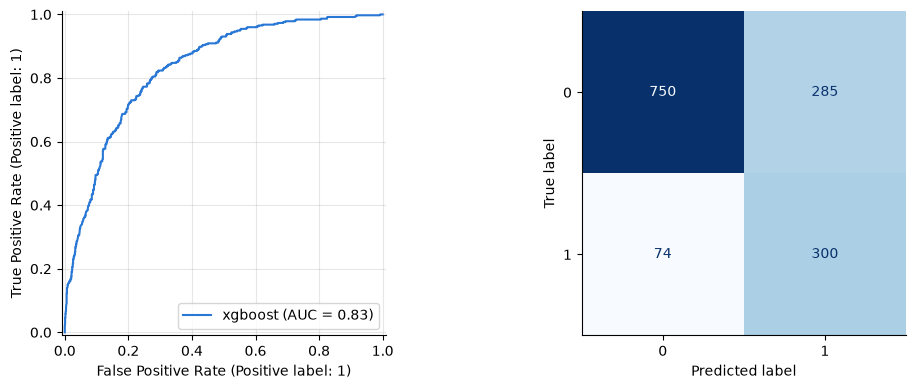

In [7]:
from ml.pipelines.common import classification_metrics
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
best = comparison.iloc[0]["model"]
pw = float((y_train == 0).sum() / (y_train == 1).sum())
model = churn.build(churn.candidates(pw)[best]).fit(X_train, y_train)
proba = model.predict_proba(X_test)[:, 1]
test = classification_metrics(y_test, proba)
print(best, {k: round(v, 4) for k, v in test.items() if isinstance(v, float)})
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
RocCurveDisplay.from_predictions(y_test, proba, ax=axes[0], name=best, curve_kwargs={"color": BLUE})
ConfusionMatrixDisplay.from_predictions(y_test, (proba >= 0.5).astype(int), ax=axes[1], cmap="Blues", colorbar=False)
axes[1].grid(False); plt.tight_layout()

## 5. Final choice

Highest CV ROC-AUC wins. With class weights the model trades precision for **recall**: for
churn that's the right trade (missing a leaving customer costs more than an extra check-in).
In the CRM, *committed* = repeat buyer or a deal currently in proposal/negotiation.

In [8]:
metrics = churn.train(save=True)
{k: metrics[k] for k in ("chosen_model", "rows")} | {"test_roc_auc": metrics["test"]["roc_auc"], "test_recall": metrics["test"]["recall"]}

{'chosen_model': 'xgboost',
 'rows': 7043,
 'test_roc_auc': 0.8338,
 'test_recall': 0.8021}